**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**22 | Four Temporal Architectures: Engineering Validation**

![Stage 22 scientific workflow](https://raw.githubusercontent.com/RezaSaadatyar/human-movement-intelligence/main/wearable_activity_recognition/images/22_workflow.svg)

**Objective:** Implement and check four neural architectures for six-channel, two-second HARTH activity windows: TCN, Multi-Scale CNN, 1D-ResNet and Time-Series Transformer.

**Dataset:** Pinned HARTH v2.0 Development recordings, with a four-participant subset used for the real-source engineering smoke test. Reserved Test participants S023 and S032 are excluded.

**Notebook Scope:** Check model input/output contracts, parameter counts, illustrative CPU inference timings and single-update training behaviour. Scientific model comparisons require the matched Development benchmark in Notebook 23.

**Architecture contract:** Each model accepts float32 windows shaped `(batch, 6, 100)` and returns `(batch, 8)` raw logits. Class-index mapping must remain reversible, and Cross-Entropy receives logits without prior Softmax. The subsequent benchmark controls source windows, participant folds and preprocessing boundaries.

**00. Colab Repository Setup**

In [12]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")
%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content
/content/human-movement-intelligence


**01. Imports and Reproducible Engineering Setup**

In [13]:
# ============== 01. Imports and Reproducible Engineering Setup ===============

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("wearable_activity_recognition")

# ---------------------------- 2. Standard Library ----------------------------
import time

# ----------------- 3. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 4. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display

# ------------------------ 5. Deep Learning Framework -------------------------
import torch
from torch import nn

# --------------- 6. HARTH and Temporal Architecture Utilities ----------------
from harth_data import HARTH_SUBJECTS, ACTIVITY_NAMES, SENSOR_COLUMNS, prepare_harth_window_cohort
from core.advanced_temporal_models import (
    ARCHITECTURES, build_temporal_model, count_trainable_parameters
)
from core.temporal_cnn import TemporalCNN, standardise_imu_train_only

# ------------------------- 7. Scientific Plot Style --------------------------
from core.plot_style import plot_style
plot_style()

# ------------------ 8. Reproducibility and Device Selection ------------------
SEED=42
torch.manual_seed(SEED)
np.random.seed(SEED)
from core.computer_device import computer_device
device = computer_device()
DEVICE = device.type

# -------------------- 9. Research Task and Setup Summary ---------------------
CLASSES=tuple(range(1,9))
RESERVED_TEST={"S023","S032"}
assert len(SENSOR_COLUMNS)==6 and len(CLASSES)==8
print(""+"="*66)
print("STAGE 22: FOUR ADVANCED TEMPORAL ARCHITECTURES")
print("="*66)

print("New architectures:",", ".join(ARCHITECTURES))
print("Reserved Test excluded:",sorted(RESERVED_TEST))


Compute device and system information
OS: Linux 6.6.159+
CPU: x86_64
Installed RAM: 12.7 GiB
NVIDIA GPU: Tesla T4
Total VRAM: 15.00 GiB
PyTorch version: 2.11.0+cu128
CUDA device: Tesla T4
CUDA runtime: 12.8
cuDNN version: 91900
PyTorch total VRAM: 14.56 GiB
Selected compute device: cuda
STAGE 22: FOUR ADVANCED TEMPORAL ARCHITECTURES
New architectures: TCN, Multi-Scale CNN, 1D-ResNet, Time-Series Transformer
Reserved Test excluded: ['S023', 'S032']


**02. Architecture A: Temporal Convolutional Network (TCN)**

The noncausal TCN uses residual blocks with dilations `1, 2, 4, 8`, two five-point convolutions per block, BatchNorm, GELU and Dropout. Residual projections handle changes in channel width. Global temporal pooling feeds the eight-class output layer. This architecture classifies completed windows and is not a streaming forecaster.

In [14]:
# ========= 02. Architecture A: Temporal Convolutional Network (TCN) ==========

# ------------------- 1. Build Temporal Convolutional Model -------------------
tcn=build_temporal_model("TCN",in_channels=6,n_classes=8)

# --------------- 2. Validate Input and Forward-Pass Behaviour ----------------
sample=torch.randn(3,6,100)
with torch.no_grad():
    tcn.eval()
    tcn_logits=tcn(sample)

assert tcn_logits.shape==(3,8)
print("TCN input:",tuple(sample.shape))
print("TCN logits:",tuple(tcn_logits.shape))
print("TCN trainable parameters:",f"{count_trainable_parameters(tcn):,}")
print("Temporal dilations:",[1,2,4,8])
print("Noncausal full-window classification: YES")


TCN input: (3, 6, 100)
TCN logits: (3, 8)
TCN trainable parameters: 38,056
Temporal dilations: [1, 2, 4, 8]
Noncausal full-window classification: YES


**03. Architecture B: Multi-Scale CNN (InceptionTime-Inspired)**

Three branches with kernels of sizes 3, 7 and 15, together with a max-pooling branch, capture patterns at different temporal scales. The model uses an input bottleneck, residual connections, BatchNorm and global average pooling. It is a compact InceptionTime-inspired design, not a reproduction of the complete published ensemble.

In [15]:
# ======= 03. Architecture B: Multi-Scale CNN (InceptionTime-Inspired) ========

# ------------------------- 1. Build Multi-Scale CNN --------------------------
multi=build_temporal_model("Multi-Scale CNN",in_channels=6,n_classes=8)

# ------------------- 2. Validate Model Output and Capacity -------------------
multi.eval()
with torch.no_grad():
    multiscale_logits=multi(sample)

assert multiscale_logits.shape==(3,8)

print("Multi-Scale CNN logits:",tuple(multiscale_logits.shape))
print("Parallel kernel sizes:",[3,7,15])
print("Additional pooling branch: YES")
print("Trainable parameters:",f"{count_trainable_parameters(multi):,}")
print("Full original InceptionTime ensemble implemented: NO")


Multi-Scale CNN logits: (3, 8)
Parallel kernel sizes: [3, 7, 15]
Additional pooling branch: YES
Trainable parameters: 16,488
Full original InceptionTime ensemble implemented: NO


**04. Architecture C: 1D-ResNet**

An initial temporal convolution is followed by three residual stages. The second stage increases channel width and downsamples in time; projection shortcuts maintain compatible tensor shapes. Global pooling feeds the classifier. This is a lightweight time-series ResNet rather than an image-based architecture, and residual connections do not guarantee higher accuracy.

In [16]:
# ======================= 04. Architecture C: 1D-ResNet =======================

# --------------------- 1. Build Residual Temporal Model ----------------------
resnet=build_temporal_model("1D-ResNet",in_channels=6,n_classes=8)

# --------------- 2. Validate Forward Pass and Parameter Count ----------------
resnet.eval()

with torch.no_grad():
    resnet_logits=resnet(sample)
assert resnet_logits.shape==(3,8)

print("1D-ResNet logits:",tuple(resnet_logits.shape))
print("Trainable parameters:",f"{count_trainable_parameters(resnet):,}")
print("Strided temporal downsampling: YES")
print("Full-window global pooling: YES")


1D-ResNet logits: (3, 8)
Trainable parameters: 91,176
Strided temporal downsampling: YES
Full-window global pooling: YES


**05. Architecture D: Time-Series Transformer**

Project each six-channel time point to a 48-dimensional embedding and add fixed sinusoidal positional encodings. Two bidirectional Transformer encoder layers with four attention heads process the 100-sample sequence, followed by normalisation, average pooling and eight output logits. Attention weights are not treated as faithful explanations of model reasoning.

In [17]:
# ================ 05. Architecture D: Time-Series Transformer ================

# --------------------- 1. Build Time-Series Transformer ----------------------
transformer=build_temporal_model(
    "Time-Series Transformer",in_channels=6,n_classes=8,
    d_model=48,n_heads=4,n_layers=2,feedforward_dim=96,max_length=256
)

# ----------------- 2. Validate Attention and Output Contract -----------------
transformer.eval()

with torch.no_grad():
    transformer_logits=transformer(sample)
assert transformer_logits.shape==(3,8)

print("Transformer logits:",tuple(transformer_logits.shape))
print("Attention heads:",4,"| Encoder layers:",2)
print("Embedding dimension:",48)
print("Trainable parameters:",f"{count_trainable_parameters(transformer):,}")
print("Causal real-time behaviour established: NO")


Transformer logits: (3, 8)
Attention heads: 4 | Encoder layers: 2
Embedding dimension: 48
Trainable parameters: 38,744
Causal real-time behaviour established: NO


**06. Inspect Architecture Size and CPU Forward-Pass Timing**

Count trainable parameters and measure illustrative CPU forward passes using the same synthetic float32 input in evaluation mode. Timing depends on local hardware, threads, warm-up and PyTorch version, so these probes are not controlled production-latency benchmarks.

The previously implemented Simple Temporal CNN is included as a fifth reference model in the capacity and timing comparison. One-update source-data smoke tests are performed only for the four additional architectures.

,architecture,trainable_parameters,cpu_ms_per_16_windows,logits_shape
0,Simple Temporal CNN,12392,1.12,"(16, 8)"
1,TCN,38056,7.58,"(16, 8)"
2,Multi-Scale CNN,16488,5.44,"(16, 8)"
3,1D-ResNet,91176,5.04,"(16, 8)"
4,Time-Series Transformer,38744,9.33,"(16, 8)"


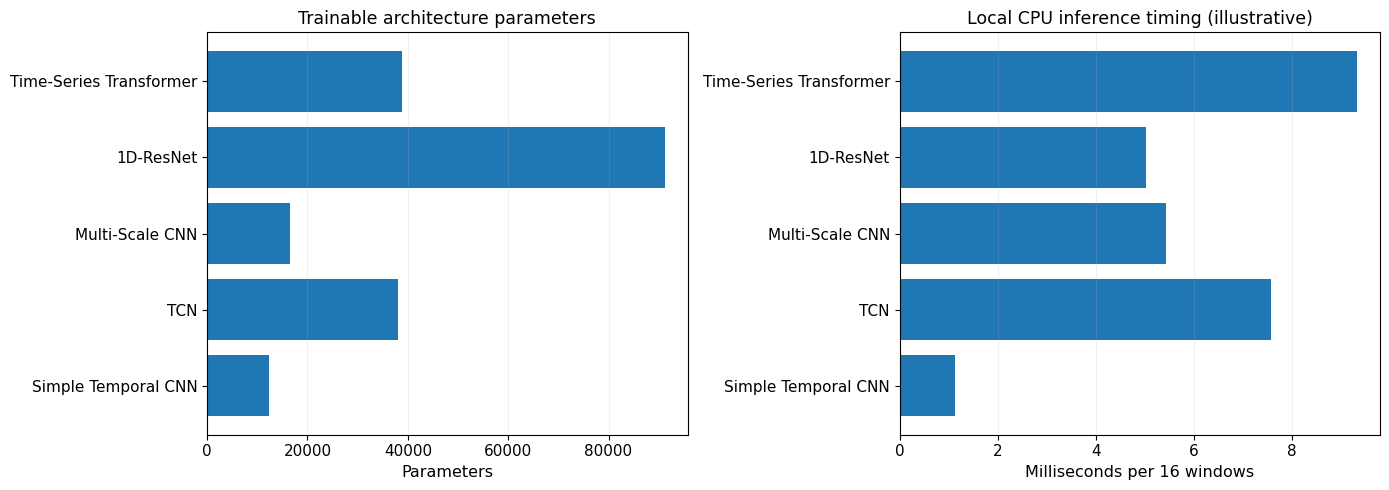

In [18]:
# ========= 06. Inspect Architecture Size and CPU Forward-Pass Timing =========

# ------------------- 1. Configure Comparative Model Timing -------------------
reference={"Simple Temporal CNN":TemporalCNN(6,8)}
models={name:build_temporal_model(name,6,8) for name in ARCHITECTURES}
models={**reference,**models}
timing_input=torch.randn(16,6,100)
rows=[]

# --------------------- 2. Measure CPU Forward-Pass Costs ---------------------
for name,model in models.items():
    model=model.cpu().eval()
    with torch.no_grad():
        for _ in range(2):
            logits=model(timing_input)
        starts=time.perf_counter()
        for _ in range(5):
            logits=model(timing_input)
        elapsed=(time.perf_counter()-starts)/5*1000  # Average over five CPU forward passes, in milliseconds.
    assert logits.shape==(16,8) and torch.isfinite(logits).all()
    rows.append({
        "architecture":name,
        "trainable_parameters":count_trainable_parameters(model),
        "cpu_ms_per_16_windows":elapsed,
        "logits_shape":str(tuple(logits.shape))
    })
capacity=pd.DataFrame(rows)
display(capacity.round(2))

# ----------------------- 3. Summarise Model Complexity -----------------------
fig,axes=plt.subplots(1,2,figsize=(14,5))
axes[0].barh(capacity["architecture"],capacity["trainable_parameters"])
axes[0].set(title="Trainable architecture parameters",xlabel="Parameters")
axes[1].barh(capacity["architecture"],capacity["cpu_ms_per_16_windows"])
axes[1].set(title="Local CPU inference timing (illustrative)",xlabel="Milliseconds per 16 windows")
for ax in axes:
    ax.grid(axis="x",alpha=0.2)
fig.tight_layout()
plt.show()


**07. Prepare Participant-Disjoint HARTH Source Windows**

Use real-source windows from Development participants S006, S008, S012 and S013. The smoke-test subset contains 96 Train and 32 Validation windows separated by participant identity, with label purity and timestamp continuity enforced. Its size and class coverage do not support reliable model-performance comparisons.

In [19]:
# =========== 07. Prepare Participant-Disjoint HARTH Source Windows ===========

# -------------------- 1. Select Development Participants ---------------------
SMOKE_PEOPLE=["S006","S008","S012","S013"]
assert not(set(SMOKE_PEOPLE)&RESERVED_TEST)

# ------------------ 2. Prepare Participant-Disjoint Windows ------------------
X,y,metadata,overview=prepare_harth_window_cohort(
    subjects=SMOKE_PEOPLE,data_dir=root/"data/raw/harth_v2",
    task_classes=CLASSES,max_windows_per_subject=32,
    window_size=100,step_size=50,sampling_rate=50
)

display(overview[["subject_id","eligible_windows","sampled_windows"]])
training_people={"S006","S008","S012"}
validation_people={"S013"}

# ------------------- 3. Check Signal Alignment and Scaling -------------------
train_idx=np.flatnonzero(metadata["subject_id"].isin(training_people).to_numpy())
val_idx=np.flatnonzero(metadata["subject_id"].isin(validation_people).to_numpy())

assert not(training_people&validation_people)
assert len(X)==len(metadata)==len(y)==128
assert X.shape[1:]==(6,100) and len(train_idx)==96 and len(val_idx)==32
assert set(np.unique(y)).issubset(CLASSES)
X_train,X_validation,train_statistics=standardise_imu_train_only(  # Fit normalisation statistics on Train participants only.
    X[train_idx],X[val_idx]
)

print("Real source Train:",X_train.shape,"| Validation:",X_validation.shape)
print("Actual classes observed in Train:",sorted(np.unique(y[train_idx]).tolist()))
print("All eight classes required in tiny smoke test: NO")


Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S012.csv
HARTH subject S012: 382,414 rows, 6 sensors
Input signal: 382,414 samples, 6 channels
Candidate windows: 7,647
Retained windows: 7,309 | Shape: (7309, 6, 100)
Rejected candidates: 338
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S013.csv
HARTH subject S013: 369,077 rows, 6 sensors
Input signal: 369,077 samples, 6 channels
Candid

,subject_id,eligible_windows,sampled_windows
0,S006,6708,32
1,S008,7392,32
2,S012,7309,32
3,S013,6402,32


Real source Train: (96, 6, 100) | Validation: (32, 6, 100)
Actual classes observed in Train: [1, 3, 5, 6, 7, 8]
All eight classes required in tiny smoke test: NO


**08. Run One-Update Architecture Smoke Tests**

For each architecture, check finite Cross-Entropy loss, gradient propagation, trainable-parameter updates and output shapes using a single optimiser step. This verifies that the implementation runs on source data; it does not demonstrate training convergence, rare-class recall or predictive superiority.

In [20]:
# ================ 08. Run One-Update Architecture Smoke Tests ================

# -------------------- 1. Prepare Label and Tensor Inputs ---------------------
mapping={code:i for i,code in enumerate(CLASSES)}
batch_x=torch.from_numpy(X_train[:16])
batch_y=torch.tensor([mapping[int(label)] for label in y[train_idx[:16]]],dtype=torch.long)
val_tensor=torch.from_numpy(X_validation)

# ------------------- 2. Run One-Step Training Smoke Tests --------------------
training_rows=[]
for name in ARCHITECTURES:
    torch.manual_seed(SEED)
    network=build_temporal_model(name,6,8).cpu()
    optimizer=torch.optim.Adam(network.parameters(),lr=1e-3)
    before=[weight.detach().clone() for weight in network.parameters()]
    network.train()
    optimizer.zero_grad(set_to_none=True)
    loss=nn.CrossEntropyLoss()(network(batch_x),batch_y)
    assert torch.isfinite(loss).item()
    loss.backward()
    assert all(
        parameter.grad is not None and torch.isfinite(parameter.grad).all().item()
        for parameter in network.parameters() if parameter.requires_grad
    )
    optimizer.step()
    changed=any(not torch.equal(old,current.detach())
                for old,current in zip(before,network.parameters()))

# Infer on held-out participants without fitting on Validation.
    network.eval()
    with torch.no_grad():
        validation_logits=network(val_tensor)
    assert changed and validation_logits.shape==(len(val_idx),8)
    training_rows.append({
        "architecture":name,"initial_batch_loss":float(loss.item()),
        "optimizer_updates":1,"parameters_changed":changed,
        "held_out_output_shape":str(tuple(validation_logits.shape)),
        "finite_validation_logits":bool(torch.isfinite(validation_logits).all().item())
    })

# ----------------------- 3. Check Logits and Gradients -----------------------
smoke=pd.DataFrame(training_rows)

display(smoke.round(4))
print("Smoke training is not a predictive-performance benchmark.")


,architecture,initial_batch_loss,optimizer_updates,parameters_changed,held_out_output_shape,finite_validation_logits
0,TCN,2.2892,1,True,"(32, 8)",True
1,Multi-Scale CNN,1.8222,1,True,"(32, 8)",True
2,1D-ResNet,2.1541,1,True,"(32, 8)",True
3,Time-Series Transformer,2.4519,1,True,"(32, 8)",True


Smoke training is not a predictive-performance benchmark.


**09. Document Architectural Differences and Benchmark Controls**

TCN uses dilated temporal context; Multi-Scale CNN combines kernel widths; 1D-ResNet uses residual stages; and Transformer combines global token interactions with positional information. These are distinct modelling hypotheses. Notebook 23 subsequently evaluated the architectures using matched source rows, participant-held-out folds and consistent metric definitions.

In [21]:
# ======= 09. Document Architectural Differences and Benchmark Controls =======

# ------------------- 1. Summarise Architecture Hypotheses --------------------
design_map=pd.DataFrame([
    {"architecture":"TCN","hypothesis":"Dilated temporal context helps distinguish related movement sequences","principal_risk":"Noncausal window context and receptive-field assumptions"},
    {"architecture":"Multi-Scale CNN","hypothesis":"Parallel kernels capture multiple movement timescales","principal_risk":"More filters, extra optimisation and potentially noisy small activities"},
    {"architecture":"1D-ResNet","hypothesis":"Residual depth learns expressive sequence features","principal_risk":"Overfitting and stride-related information loss"},
    {"architecture":"Time-Series Transformer","hypothesis":"Bidirectional self-attention captures longer-range within-window patterns","principal_risk":"Computational cost and data hunger"},
])

display(design_map)

# ---------------- 2. Document Matched Benchmark Requirements -----------------
controls=pd.DataFrame([
    {"constraint":"Same windows and subject folds","status":"Required"},
    {"constraint":"Train-only sensor standardisation and class weights","status":"Required"},
    {"constraint":"Fixed eight-code class denominator and Macro F1","status":"Required"},
    {"constraint":"Per-class Shuffling/stairs performance and support","status":"Required"},
    {"constraint":"Compute/parameters/latency reporting","status":"Required"},
    {"constraint":"Original Test subjects S023/S032 excluded","status":"Required"},
    {"constraint":"Reproducibility over more than one seed","status":"Stage 24"},
])

display(controls)


,architecture,hypothesis,principal_risk
0,TCN,Dilated temporal context helps distinguish rel...,Noncausal window context and receptive-field a...
1,Multi-Scale CNN,Parallel kernels capture multiple movement tim...,"More filters, extra optimisation and potential..."
2,1D-ResNet,Residual depth learns expressive sequence feat...,Overfitting and stride-related information loss
3,Time-Series Transformer,Bidirectional self-attention captures longer-r...,Computational cost and data hunger


,constraint,status
0,Same windows and subject folds,Required
1,Train-only sensor standardisation and class we...,Required
2,Fixed eight-code class denominator and Macro F1,Required
3,Per-class Shuffling/stairs performance and sup...,Required
4,Compute/parameters/latency reporting,Required
5,Original Test subjects S023/S032 excluded,Required
6,Reproducibility over more than one seed,Stage 24


**10. Engineering Quality Gate and Evidence Boundary**

Verify all four models, finite logits and gradients, parameter updates, participant separation and reserved Test exclusion. Passing engineering checks does not establish classifier accuracy or generalisation.

Notebook 23 subsequently performed the matched seven-model Development comparison, reporting class-level and participant-level metrics alongside training costs.

In [22]:
# ============ 10. Engineering Quality Gate and Evidence Boundary =============

# ---------------- 1. Verify Architecture and Input Integrity -----------------
assert len(ARCHITECTURES)==4
assert set(ARCHITECTURES)==set(smoke["architecture"])
assert set(capacity["architecture"])==set(ARCHITECTURES)|{"Simple Temporal CNN"}
assert all(capacity["trainable_parameters"]>0)
assert capacity["logits_shape"].eq("(16, 8)").all()
assert X.shape==(128,6,100)
assert metadata["subject_id"].nunique()==4
assert not(set(metadata["subject_id"])&RESERVED_TEST)
assert not(training_people&validation_people)
assert np.isfinite(X_train).all() and np.isfinite(X_validation).all()

# -------------------- 2. Check Training Steps and Logits ---------------------
assert smoke["optimizer_updates"].eq(1).all()
assert smoke["parameters_changed"].all()
assert smoke["finite_validation_logits"].all()
assert smoke["held_out_output_shape"].eq("(32, 8)").all()

# -------------------- 3. Quality Gate and Evidence Limits --------------------
print(""+"="*66)
print("STAGE 22: FOUR ADVANCED TEMPORAL ARCHITECTURES")
print("="*66)
print("Temporal Convolutional Network: IMPLEMENTED AND SMOKE-TESTED")
print("Multi-Scale CNN: IMPLEMENTED AND SMOKE-TESTED")
print("1D-ResNet: IMPLEMENTED AND SMOKE-TESTED")
print("Time-Series Transformer: IMPLEMENTED AND SMOKE-TESTED")
print("Common (batch, channels, time) contract: PASSED")
print("Real-data Train/Validation participant separation: PASSED")
print("Finite gradients and one-step updates: PASSED")
print("Original protected Test used: NO")
print("-"*66)
print("Stage 22 engineering quality gate: PASSED")
print("Full matched model benchmark performed: NO")
print("Independent predictive generalisation established: NO")
print("Next stage: Stage 23 - Unified Model Benchmark")


STAGE 22: FOUR ADVANCED TEMPORAL ARCHITECTURES
Temporal Convolutional Network: IMPLEMENTED AND SMOKE-TESTED
Multi-Scale CNN: IMPLEMENTED AND SMOKE-TESTED
1D-ResNet: IMPLEMENTED AND SMOKE-TESTED
Time-Series Transformer: IMPLEMENTED AND SMOKE-TESTED
Common (batch, channels, time) contract: PASSED
Real-data Train/Validation participant separation: PASSED
Finite gradients and one-step updates: PASSED
Original protected Test used: NO
------------------------------------------------------------------
Stage 22 engineering quality gate: PASSED
Full matched model benchmark performed: NO
Independent predictive generalisation established: NO
Next stage: Stage 23 - Unified Model Benchmark
